# UNIT II
## NumPy Arrays, Indexing and Speed
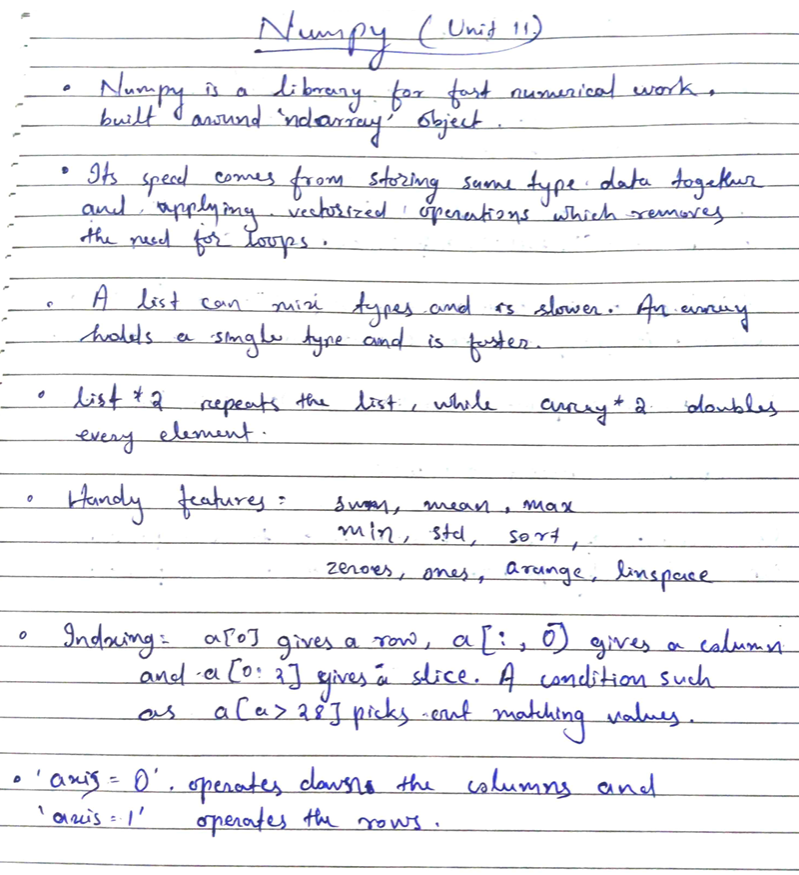

In [ ]:
import numpy as np
import time

tp = np.array([22, 31, 27, 35, 29, 24])
print("Array:", tp)
print("Type:", type(tp))
print("Shape:", tp.shape)
print("Dtype:", tp.dtype)

print("Sum:", tp.sum())
print("Mean:", tp.mean())
print("Max:", tp.max())
print("Min:", tp.min())
print("Std:", tp.std())
print("Sorted:", np.sort(tp))

print("tp + 5:", tp + 5)
print("tp * 2:", tp * 2)
print("tp / 10:", tp / 10)

Array: [22 31 27 35 29 24]
Type: <class 'numpy.ndarray'>
Shape: (6,)
Dtype: int64
Sum: 168
Mean: 28.0
Max: 35
Min: 22
Std: 4.320493798938574
Sorted: [22 24 27 29 31 35]
tp + 5: [27 36 32 40 34 29]
tp * 2: [44 62 54 70 58 48]
tp / 10: [2.2 3.1 2.7 3.5 2.9 2.4]


In [ ]:
print("Zeros:", np.zeros(4))
print("Ones:", np.ones(4))
print("arange 0 to 9:", np.arange(0, 10))
print("arange step 3:", np.arange(0, 12, 3))
print("linspace:", np.linspace(0, 1, 5))

sl = np.array([[12, 18, 15],
               [20, 10, 25],
               [30, 22, 17]])
print(sl)
print("Shape:", sl.shape)

Zeros: [0. 0. 0. 0.]
Ones: [1. 1. 1. 1.]
arange 0 to 9: [0 1 2 3 4 5 6 7 8 9]
arange step 3: [0 3 6 9]
linspace: [0.   0.25 0.5  0.75 1.  ]
[[12 18 15]
 [20 10 25]
 [30 22 17]]
Shape: (3, 3)


In [ ]:
print("First row:", sl[0])
print("Element [1, 2]:", sl[1, 2])
print("First column:", sl[:, 0])
print("First two rows:")
print(sl[0:2])

print("Row-wise mean (axis=1):", sl.mean(axis=1))
print("Column-wise mean (axis=0):", sl.mean(axis=0))

print("Above 28:", tp[tp > 28])
print("Boolean mask:", tp > 28)

First row: [12 18 15]
Element [1, 2]: 25
First column: [12 20 30]
First two rows:
[[12 18 15]
 [20 10 25]]
Row-wise mean (axis=1): [15.         18.33333333 23.        ]
Column-wise mean (axis=0): [20.66666667 16.66666667 19.        ]
Above 28: [31 35 29]
Boolean mask: [False  True False  True  True False]


In [ ]:
bl = list(range(1000000))
ba = np.arange(1000000)

s = time.time()
nl = []
for v in bl:
    nl.append(v * 2)
lt = time.time() - s
print("List time:", round(lt, 4), "seconds")

s = time.time()
na = ba * 2
nt = time.time() - s
print("NumPy time:", round(nt, 4), "seconds")

print("NumPy is about", round(lt / nt), "times faster")

List time: 0.0623 seconds
NumPy time: 0.0025 seconds
NumPy is about 25 times faster


## Pandas DataFrame: Import, Filter, loc and iloc

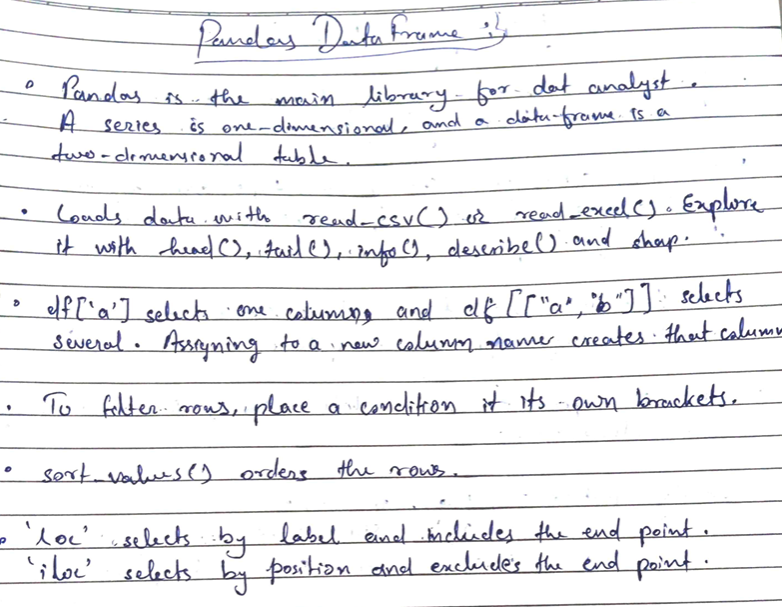

In [ ]:
import pandas as pd

d = {
    "name": ["Arun", "Bela", "Chet", "Diya", "Esha", "Faiz"],
    "dept": ["HR", "IT", "IT", "HR", "Ops", "IT"],
    "exp":  [2, 6, 4, 8, 3, 5],
    "sal":  [30, 55, 48, 60, 35, 52]
}
df = pd.DataFrame(d)
print(df)

df.to_csv("emp.csv", index=False)
df = pd.read_csv("emp.csv")
print("Data loaded from CSV")

   name dept  exp  sal
0  Arun   HR    2   30
1  Bela   IT    6   55
2  Chet   IT    4   48
3  Diya   HR    8   60
4  Esha  Ops    3   35
5  Faiz   IT    5   52
Data loaded from CSV


In [ ]:
print(df.head(3))
print(df.tail(2))
print("Shape:", df.shape)
print("Columns:", list(df.columns))
df.info()
print(df.describe())

print(df["name"])
print(df[["name", "sal"]])

   name dept  exp  sal
0  Arun   HR    2   30
1  Bela   IT    6   55
2  Chet   IT    4   48
   name dept  exp  sal
4  Esha  Ops    3   35
5  Faiz   IT    5   52
Shape: (6, 4)
Columns: ['name', 'dept', 'exp', 'sal']
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   name    6 non-null      str  
 1   dept    6 non-null      str  
 2   exp     6 non-null      int64
 3   sal     6 non-null      int64
dtypes: int64(2), str(2)
memory usage: 324.0 bytes
            exp        sal
count  6.000000   6.000000
mean   4.666667  46.666667
std    2.160247  11.758685
min    2.000000  30.000000
25%    3.250000  38.250000
50%    4.500000  50.000000
75%    5.750000  54.250000
max    8.000000  60.000000
0    Arun
1    Bela
2    Chet
3    Diya
4    Esha
5    Faiz
Name: name, dtype: str
   name  sal
0  Arun   30
1  Bela   55
2  Chet   48
3  Diya   60
4  Esha   35
5  Faiz   52


In [ ]:
df["bonus"] = df["sal"] * 0.1
df["lvl"] = "Junior"
df.loc[df["exp"] >= 5, "lvl"] = "Senior"
print(df)

print(df[df["sal"] > 50])
print(df[df["dept"] == "IT"])
print(df[(df["dept"] == "IT") & (df["exp"] > 4)])
print(df[(df["dept"] == "HR") | (df["dept"] == "Ops")])

print(df.sort_values("sal", ascending=False))

   name dept  exp  sal  bonus     lvl
0  Arun   HR    2   30    3.0  Junior
1  Bela   IT    6   55    5.5  Senior
2  Chet   IT    4   48    4.8  Junior
3  Diya   HR    8   60    6.0  Senior
4  Esha  Ops    3   35    3.5  Junior
5  Faiz   IT    5   52    5.2  Senior
   name dept  exp  sal  bonus     lvl
1  Bela   IT    6   55    5.5  Senior
3  Diya   HR    8   60    6.0  Senior
5  Faiz   IT    5   52    5.2  Senior
   name dept  exp  sal  bonus     lvl
1  Bela   IT    6   55    5.5  Senior
2  Chet   IT    4   48    4.8  Junior
5  Faiz   IT    5   52    5.2  Senior
   name dept  exp  sal  bonus     lvl
1  Bela   IT    6   55    5.5  Senior
5  Faiz   IT    5   52    5.2  Senior
   name dept  exp  sal  bonus     lvl
0  Arun   HR    2   30    3.0  Junior
3  Diya   HR    8   60    6.0  Senior
4  Esha  Ops    3   35    3.5  Junior
   name dept  exp  sal  bonus     lvl
3  Diya   HR    8   60    6.0  Senior
1  Bela   IT    6   55    5.5  Senior
5  Faiz   IT    5   52    5.2  Senior
2  Chet   IT

In [ ]:
print("Name at row 2:", df.loc[2, "name"])
print(df.loc[0:2, ["name", "sal"]])
print(df.iloc[0:2, 0:3])

print("Average salary:", df["sal"].mean())
print("Max experience:", df["exp"].max())
print(df["dept"].value_counts())

Name at row 2: Chet
   name  sal
0  Arun   30
1  Bela   55
2  Chet   48
   name dept  exp
0  Arun   HR    2
1  Bela   IT    6
Average salary: 46.666666666666664
Max experience: 8
dept
IT     3
HR     2
Ops    1
Name: count, dtype: int64


## Pandas GroupBy, Pivot and Merge

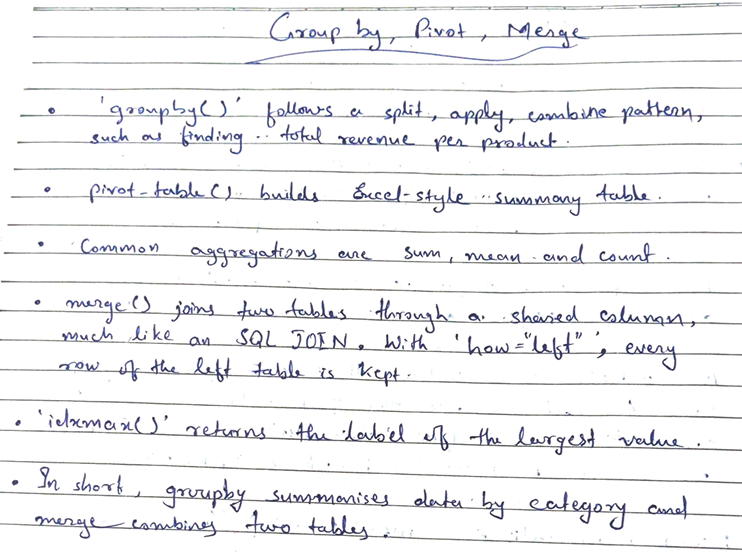

In [ ]:
od = pd.DataFrame({
    "prod": ["Tea", "Jam", "Tea", "Rice", "Jam", "Rice"],
    "zone": ["East", "West", "East", "West", "East", "West"],
    "qty":  [20, 15, 30, 10, 25, 40],
    "rate": [5, 8, 5, 12, 8, 12]
})
od["rev"] = od["qty"] * od["rate"]
print(od)

print(od.groupby("prod")["rev"].sum())
print(od.groupby("prod")["rev"].mean())
print(od.groupby("prod")["rev"].count())
print(od.groupby("zone")["qty"].sum())
print(od.groupby("zone")["rev"].sum())

   prod  zone  qty  rate  rev
0   Tea  East   20     5  100
1   Jam  West   15     8  120
2   Tea  East   30     5  150
3  Rice  West   10    12  120
4   Jam  East   25     8  200
5  Rice  West   40    12  480
prod
Jam     320
Rice    600
Tea     250
Name: rev, dtype: int64
prod
Jam     160.0
Rice    300.0
Tea     125.0
Name: rev, dtype: float64
prod
Jam     2
Rice    2
Tea     2
Name: rev, dtype: int64
zone
East    75
West    65
Name: qty, dtype: int64
zone
East    450
West    720
Name: rev, dtype: int64


In [ ]:
pv = od.pivot_table(values="rev", index="prod", columns="zone", aggfunc="sum", fill_value=0)
print(pv)

inf = pd.DataFrame({
    "prod": ["Tea", "Jam", "Rice"],
    "typ":  ["Drink", "Food", "Food"]
})
mg = od.merge(inf, on="prod", how="left")
print(mg)

print(mg.groupby("typ")["rev"].sum())

pr = od.groupby("prod")["rev"].sum()
print("Best product:", pr.idxmax())
print("Its revenue:", pr.max())

zone  East  West
prod            
Jam    200   120
Rice     0   600
Tea    250     0
   prod  zone  qty  rate  rev    typ
0   Tea  East   20     5  100  Drink
1   Jam  West   15     8  120   Food
2   Tea  East   30     5  150  Drink
3  Rice  West   10    12  120   Food
4   Jam  East   25     8  200   Food
5  Rice  West   40    12  480   Food
typ
Drink    250
Food     920
Name: rev, dtype: int64
Best product: Rice
Its revenue: 600


## Data Cleaning, Outliers and Normalization

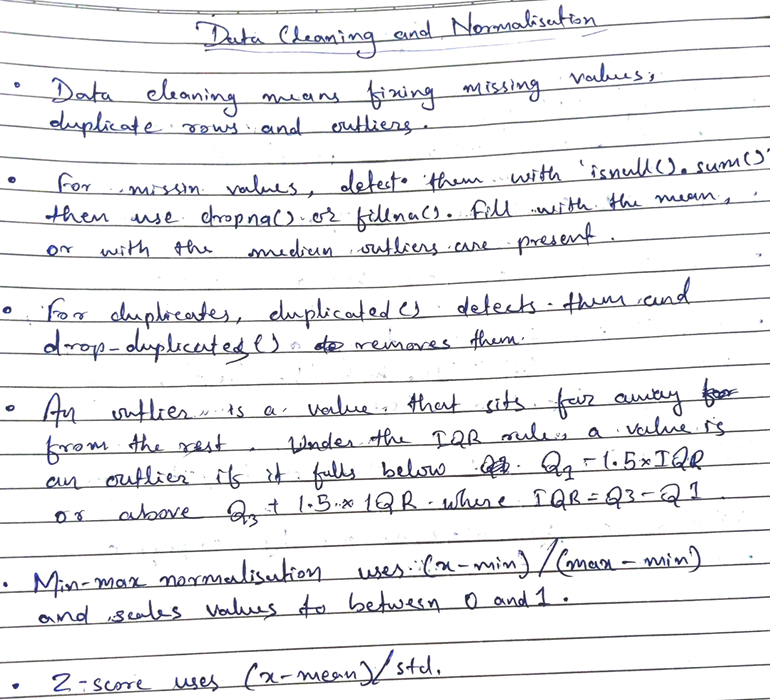

In [ ]:
import numpy as np

d = {
    "name": ["Om", "Pia", "Raj", "Pia", "Sam", "Tara"],
    "age":  [21, 22, np.nan, 22, 23, 21],
    "sal":  [23000, 26000, 24000, 26000, np.nan, 500000]
}
df = pd.DataFrame(d)
print(df)

print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
print(df)

df["age"] = df["age"].fillna(df["age"].mean())
df["sal"] = df["sal"].fillna(df["sal"].median())
print(df)
print("Missing left:", df.isnull().sum().sum())

   name   age       sal
0    Om  21.0   23000.0
1   Pia  22.0   26000.0
2   Raj   NaN   24000.0
3   Pia  22.0   26000.0
4   Sam  23.0       NaN
5  Tara  21.0  500000.0
name    0
age     1
sal     1
dtype: int64
Duplicates: 1
   name   age       sal
0    Om  21.0   23000.0
1   Pia  22.0   26000.0
2   Raj   NaN   24000.0
4   Sam  23.0       NaN
5  Tara  21.0  500000.0
   name    age       sal
0    Om  21.00   23000.0
1   Pia  22.00   26000.0
2   Raj  21.75   24000.0
4   Sam  23.00   25000.0
5  Tara  21.00  500000.0
Missing left: 0


In [ ]:
q1 = df["sal"].quantile(0.25)
q3 = df["sal"].quantile(0.75)
iqr = q3 - q1
lo = q1 - 1.5 * iqr
hi = q3 + 1.5 * iqr
print("Q1:", q1, "Q3:", q3)
print("Lower:", lo, "Upper:", hi)

out = df[(df["sal"] < lo) | (df["sal"] > hi)]
print(out)

cl = df[(df["sal"] >= lo) & (df["sal"] <= hi)].copy()
print(cl)

Q1: 24000.0 Q3: 26000.0
Lower: 21000.0 Upper: 29000.0
   name   age       sal
5  Tara  21.0  500000.0
  name    age      sal
0   Om  21.00  23000.0
1  Pia  22.00  26000.0
2  Raj  21.75  24000.0
4  Sam  23.00  25000.0


In [ ]:
mn = cl["sal"].min()
mx = cl["sal"].max()
cl["mm"] = (cl["sal"] - mn) / (mx - mn)

mu = cl["sal"].mean()
sd = cl["sal"].std()
cl["z"] = (cl["sal"] - mu) / sd

print(cl.round(2))

  name    age      sal    mm     z
0   Om  21.00  23000.0  0.00 -1.16
1  Pia  22.00  26000.0  1.00  1.16
2  Raj  21.75  24000.0  0.33 -0.39
4  Sam  23.00  25000.0  0.67  0.39


## Data Visualization

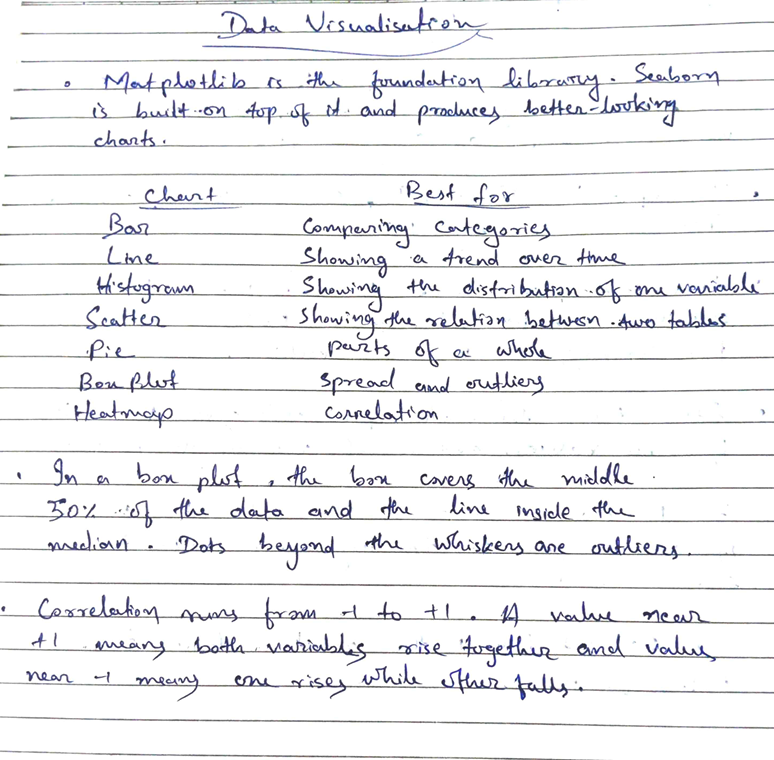

        tm  sc  hr  sl
Ann    Red  64   3   8
Ben   Blue  82   6   6
Cal    Red  58   2   8
Dan  Green  90   7   5
Eve   Blue  71   4   7
Fay  Green  49   1   9


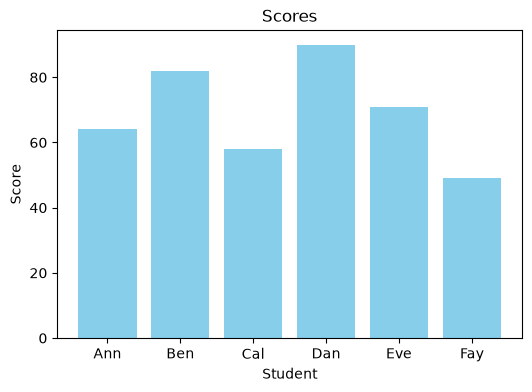

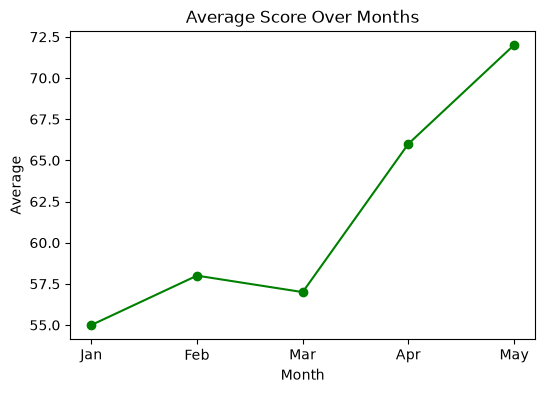

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "tm": ["Red", "Blue", "Red", "Green", "Blue", "Green"],
    "sc": [64, 82, 58, 90, 71, 49],
    "hr": [3, 6, 2, 7, 4, 1],
    "sl": [8, 6, 8, 5, 7, 9]
}, index=["Ann", "Ben", "Cal", "Dan", "Eve", "Fay"])
print(df)

plt.figure(figsize=(6, 4))
plt.bar(df.index, df["sc"], color="skyblue")
plt.title("Scores")
plt.xlabel("Student")
plt.ylabel("Score")
plt.show()

mo = ["Jan", "Feb", "Mar", "Apr", "May"]
av = [55, 58, 57, 66, 72]
plt.figure(figsize=(6, 4))
plt.plot(mo, av, marker="o", color="green")
plt.title("Average Score Over Months")
plt.xlabel("Month")
plt.ylabel("Average")
plt.show()

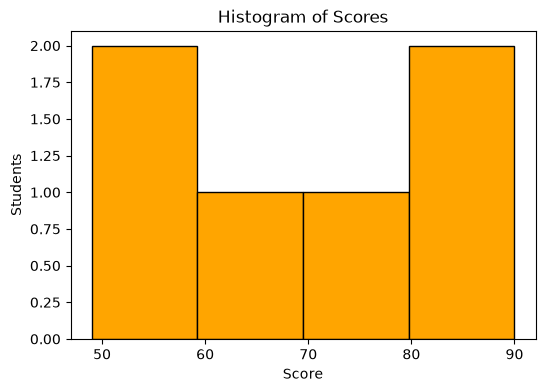

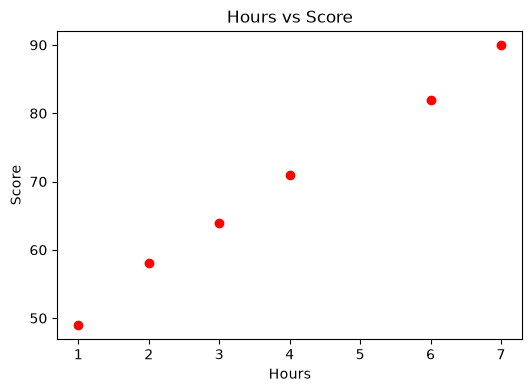

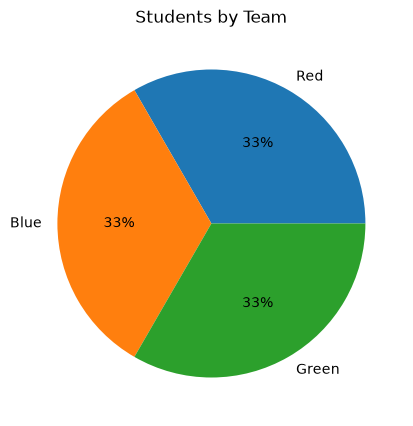

In [ ]:
plt.figure(figsize=(6, 4))
plt.hist(df["sc"], bins=4, color="orange", edgecolor="black")
plt.title("Histogram of Scores")
plt.xlabel("Score")
plt.ylabel("Students")
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(df["hr"], df["sc"], color="red")
plt.title("Hours vs Score")
plt.xlabel("Hours")
plt.ylabel("Score")
plt.show()

cn = df["tm"].value_counts()
plt.figure(figsize=(5, 5))
plt.pie(cn, labels=cn.index, autopct="%1.0f%%")
plt.title("Students by Team")
plt.show()

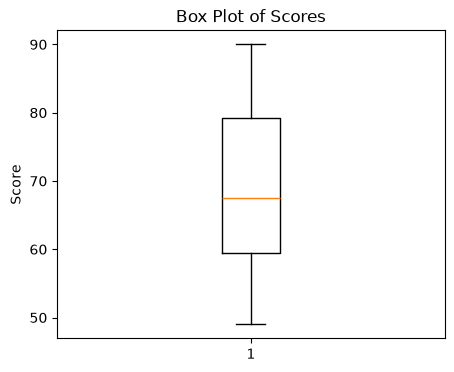

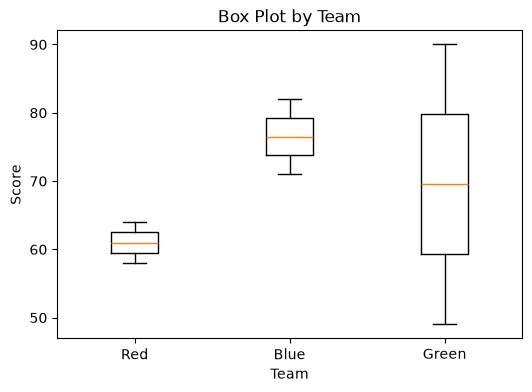

In [ ]:
plt.figure(figsize=(5, 4))
plt.boxplot(df["sc"])
plt.title("Box Plot of Scores")
plt.ylabel("Score")
plt.show()

rd = df[df["tm"] == "Red"]["sc"]
bl = df[df["tm"] == "Blue"]["sc"]
gr = df[df["tm"] == "Green"]["sc"]
plt.figure(figsize=(6, 4))
plt.boxplot([rd, bl, gr])
plt.xticks([1, 2, 3], ["Red", "Blue", "Green"])
plt.title("Box Plot by Team")
plt.xlabel("Team")
plt.ylabel("Score")
plt.show()

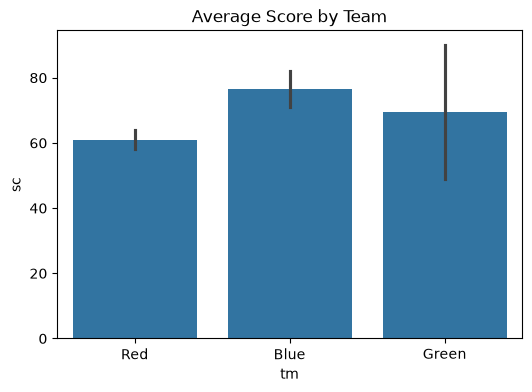

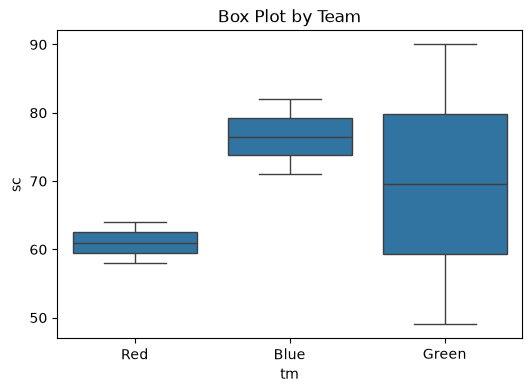

          sc        hr        sl
sc  1.000000  0.997577 -0.990177
hr  0.997577  1.000000 -0.987306
sl -0.990177 -0.987306  1.000000


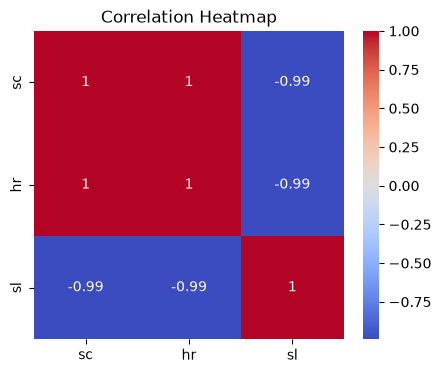

In [ ]:
plt.figure(figsize=(6, 4))
sns.barplot(x="tm", y="sc", data=df)
plt.title("Average Score by Team")
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(x="tm", y="sc", data=df)
plt.title("Box Plot by Team")
plt.show()

cr = df[["sc", "hr", "sl"]].corr()
print(cr)
plt.figure(figsize=(5, 4))
sns.heatmap(cr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()